In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
# 2. LOAD DATA
# =========================
df = pd.read_csv("/content/DATA PERKEBUNAN INDONESIA (2).csv")

print("Jumlah data:", df.shape)
print(df.head())


Jumlah data: (38, 8)
         Provinsi  Kelapa Sawit  Kelapa   Karet   Kopi  Kakao    Teh   Tebu
0            ACEH       1092.71   64.10   51.17  74.13  34.17   0.00   0.00
1  SUMATERA UTARA       5120.02  103.64  251.52  91.69  38.48  10.14  14.52
2  SUMATERA BARAT       1410.64   79.06   99.67  15.32  34.58   5.60   0.00
3            RIAU       9136.10  399.95  180.74   1.83   0.84   0.00   0.00
4           JAMBI       2113.97  115.35  222.56  23.23   0.69   4.24   0.00


In [ ]:
print(df.to_string())

                Provinsi  Kelapa Sawit  Kelapa   Karet    Kopi   Kakao    Teh     Tebu
0                   ACEH       1092.71   64.10   51.17   74.13   34.17   0.00     0.00
1         SUMATERA UTARA       5120.02  103.64  251.52   91.69   38.48  10.14    14.52
2         SUMATERA BARAT       1410.64   79.06   99.67   15.32   34.58   5.60     0.00
3                   RIAU       9136.10  399.95  180.74    1.83    0.84   0.00     0.00
4                  JAMBI       2113.97  115.35  222.56   23.23    0.69   4.24     0.00
5       SUMATERA SELATAN       3967.39   61.65  619.55  219.59    4.40   2.62   124.37
6               BENGKULU       1298.17    7.25   64.60   55.63    2.36   1.88     0.00
7                LAMPUNG        375.24   83.76   84.83  120.38   48.11   0.00   644.48
8   KEP. BANGKA BELITUNG        860.24    4.55   26.04    0.11    0.29   0.00     0.00
9              KEP. RIAU         24.19   12.16    8.41    0.00    0.01   0.00     0.00
10           DKI JAKARTA          0.00    0

In [ ]:
# 3. PREPROCESSING
# =========================
df.fillna(df.mean(numeric_only=True), inplace=True)

X = df.drop(columns=['Provinsi'])

In [ ]:
# 4. HANDLE OUTLIER (CAPPING - TIDAK MENGHAPUS DATA)
# =========================
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

X_no_outlier = X.copy()

for col in X.columns:
    X_no_outlier[col] = X_no_outlier[col].clip(
        lower=lower_bound[col],
        upper=upper_bound[col]
    )

print("Setelah capping:", X_no_outlier.shape)

Setelah capping: (38, 7)


In [ ]:
# 5. TRANSFORM DATA
# =========================
X_log = np.log1p(X_no_outlier)


In [ ]:
# 6. SCALING (DIGANTI)
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)


In [ ]:
# 7. PCA (DIUBAH JADI 2 DIMENSI)
# =========================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)



In [ ]:
# 8. NORMALISASI (TAMBAHAN)
# =========================
X_pca = normalize(X_pca)


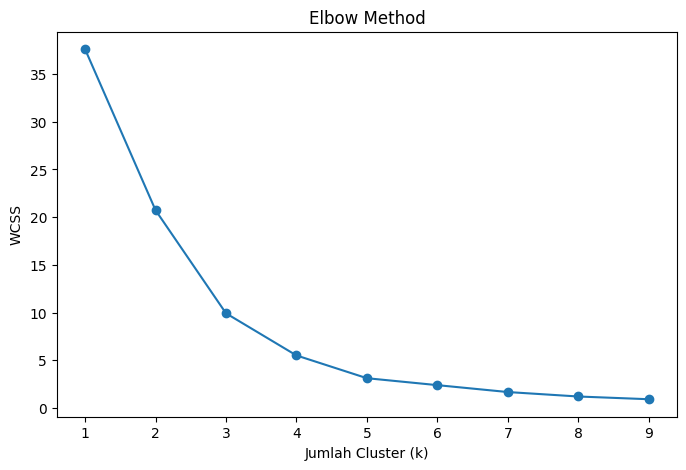

In [ ]:
# 9. ELBOW METHOD
# =========================
wcss = []

for k in range(1, 10):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=100,
        max_iter=500,
        random_state=42
    )
    kmeans.fit(X_pca)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,10), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('WCSS')
plt.savefig('elbow_method.jpg')
plt.show()

In [ ]:
from google.colab import files
files.download('elbow_method.jpg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 10. TUNING K-MEANS + EVALUASI
# =========================
results = []

print("\n=== HASIL EVALUASI CLUSTER ===")

for k in range(2, 10):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=150,
        max_iter=700,
        random_state=42
    )

    labels = kmeans.fit_predict(X_pca)

    sil = silhouette_score(X_pca, labels)
    dbi = davies_bouldin_score(X_pca, labels)

    print(f"Cluster {k}: Silhouette = {sil:.4f}, DBI = {dbi:.4f}")

    results.append((k, sil, dbi, sil - dbi))



=== HASIL EVALUASI CLUSTER ===
Cluster 2: Silhouette = 0.4290, DBI = 1.0241
Cluster 3: Silhouette = 0.5251, DBI = 0.6153
Cluster 4: Silhouette = 0.5521, DBI = 0.5642
Cluster 5: Silhouette = 0.5883, DBI = 0.4744
Cluster 6: Silhouette = 0.5612, DBI = 0.5076
Cluster 7: Silhouette = 0.5628, DBI = 0.4962
Cluster 8: Silhouette = 0.5578, DBI = 0.5281
Cluster 9: Silhouette = 0.5692, DBI = 0.4972


In [ ]:
# 11. PILIH CLUSTER TERBAIK
# =========================
best = sorted(results, key=lambda x: x[3], reverse=True)[0]
best_k = best[0]

print("\nCluster terbaik:", best_k)



Cluster terbaik: 5


In [ ]:
# 12. MODEL FINAL
# =========================
kmeans = KMeans(
    n_clusters=best_k,
    init='k-means++',
    n_init=150,
    max_iter=700,
    random_state=42
)

df['Cluster'] = kmeans.fit_predict(X_pca)

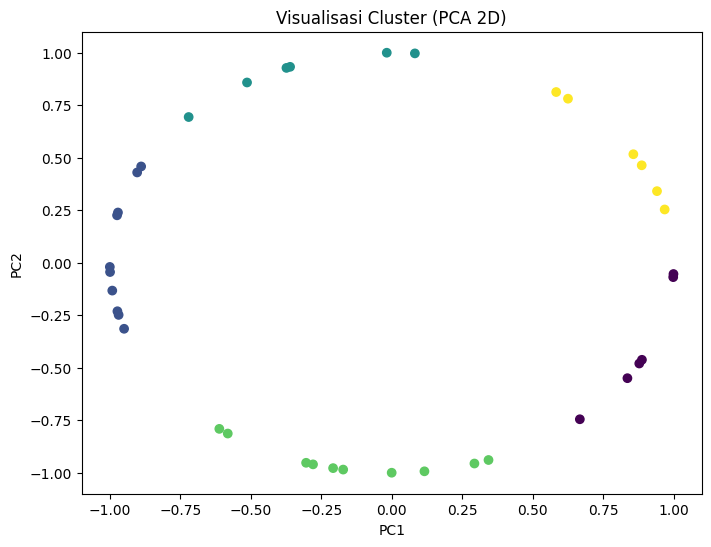

In [ ]:
# 13. VISUALISASI PCA
# =========================
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=df['Cluster'], cmap='viridis')
plt.title("Visualisasi Cluster (PCA 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [ ]:
# =========================
# 14. LABEL CLUSTER (5 CLUSTER)
# =========================
df['Total_Produksi'] = X.sum(axis=1)

cluster_mean = df.groupby('Cluster')['Total_Produksi'].mean().sort_values()

labels_map = {}

sorted_idx = cluster_mean.index

labels_map[sorted_idx[0]] = 'Sangat Rendah'
labels_map[sorted_idx[1]] = 'Rendah'
labels_map[sorted_idx[2]] = 'Sedang'
labels_map[sorted_idx[3]] = 'Tinggi'
labels_map[sorted_idx[4]] = 'Sangat Tinggi'

df['Kategori'] = df['Cluster'].map(labels_map)


In [ ]:
# 15. OUTPUT HASIL
# =========================
print("\n=== HASIL CLUSTER ===")
print(df[['Provinsi', 'Cluster', 'Kategori']])



=== HASIL CLUSTER ===
                Provinsi  Cluster       Kategori
0                   ACEH        4         Tinggi
1         SUMATERA UTARA        4         Tinggi
2         SUMATERA BARAT        4         Tinggi
3                   RIAU        2  Sangat Tinggi
4                  JAMBI        4         Tinggi
5       SUMATERA SELATAN        4         Tinggi
6               BENGKULU        4         Tinggi
7                LAMPUNG        0         Sedang
8   KEP. BANGKA BELITUNG        2  Sangat Tinggi
9              KEP. RIAU        1  Sangat Rendah
10           DKI JAKARTA        1  Sangat Rendah
11            JAWA BARAT        0         Sedang
12           JAWA TENGAH        0         Sedang
13         DI YOGYAKARTA        3         Rendah
14            JAWA TIMUR        0         Sedang
15                BANTEN        1  Sangat Rendah
16                  BALI        3         Rendah
17   NUSA TENGGARA BARAT        3         Rendah
18   NUSA TENGGARA TIMUR        3         Rend

In [ ]:
print("\n=== RATA-RATA TIAP VARIABEL PER CLUSTER ===")

mean_detail = df.groupby('Kategori').mean(numeric_only=True)

print(mean_detail)


=== RATA-RATA TIAP VARIABEL PER CLUSTER ===
               Kelapa Sawit      Kelapa       Karet       Kopi      Kakao  \
Kategori                                                                    
Rendah            50.745000   95.892000    0.083000   5.911000  21.886000   
Sangat Rendah    141.289000    9.034000    1.916000   0.668000   1.275000   
Sangat Tinggi   4595.548333   88.621667  109.155000   1.028333   0.736667   
Sedang           156.615000  128.710000   24.690000  43.636667  44.401667   
Tinggi          2500.483333   71.841667  218.178333  79.931667  19.113333   

                     Teh        Tebu  Cluster  Total_Produksi  
Kategori                                                       
Rendah          0.023000   10.151000      3.0      184.691000  
Sangat Rendah   0.001000    0.000000      1.0      154.183000  
Sangat Tinggi   0.000000    0.000000      2.0     4795.090000  
Sedang         15.698333  370.853333      0.0      784.605000  
Tinggi          4.080000   23.1

In [ ]:
print(cluster_mean)

Cluster
1     154.183000
3     184.691000
0     784.605000
4    2916.776667
2    4795.090000
Name: Total_Produksi, dtype: float64


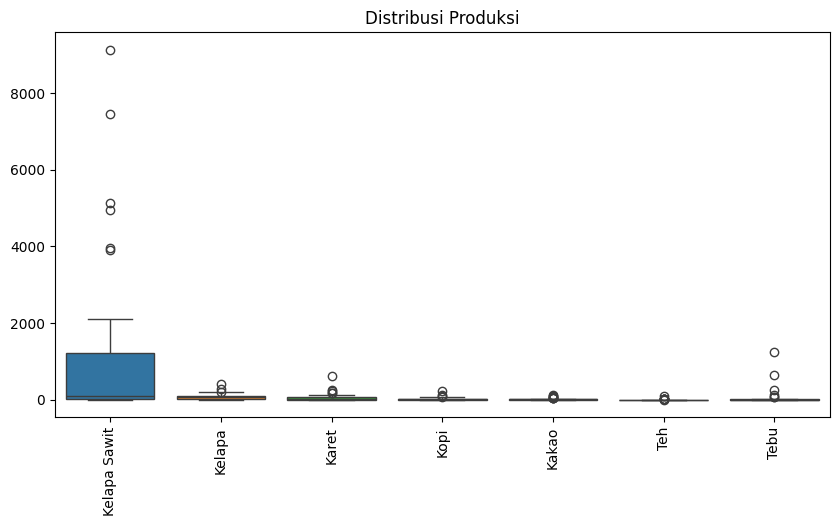

In [ ]:
# 16. VISUALISASI DISTRIBUSI
# =========================
plt.figure(figsize=(10,5))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Distribusi Produksi")
plt.show()


In [ ]:
# =========================
# 17. INSIGHT (5 CLUSTER)
# =========================
print("\n=== INSIGHT ===")

for kategori in ['Sangat Tinggi', 'Tinggi', 'Sedang', 'Rendah', 'Sangat Rendah']:
    prov = df[df['Kategori'] == kategori]['Provinsi']

    print(f"\nCluster {kategori}:")

    for p in prov:
        print("-", p)




=== INSIGHT ===

Cluster Sangat Tinggi:
- RIAU
- KEP. BANGKA BELITUNG
- KALIMANTAN BARAT
- KALIMANTAN TENGAH
- KALIMANTAN SELATAN
- KALIMANTAN TIMUR

Cluster Tinggi:
- ACEH
- SUMATERA UTARA
- SUMATERA BARAT
- JAMBI
- SUMATERA SELATAN
- BENGKULU

Cluster Sedang:
- LAMPUNG
- JAWA BARAT
- JAWA TENGAH
- JAWA TIMUR
- SULAWESI TENGAH
- SULAWESI SELATAN

Cluster Rendah:
- DI YOGYAKARTA
- BALI
- NUSA TENGGARA BARAT
- NUSA TENGGARA TIMUR
- SULAWESI UTARA
- SULAWESI TENGGARA
- GORONTALO
- SULAWESI BARAT
- MALUKU
- MALUKU UTARA

Cluster Sangat Rendah:
- KEP. RIAU
- DKI JAKARTA
- BANTEN
- KALIMANTAN UTARA
- PAPUA BARAT
- PAPUA BARAT DAYA
- PAPUA
- PAPUA SELATAN
- PAPUA TENGAH
- PAPUA PEGUNUNGAN


In [ ]:
pca.explained_variance_ratio_

array([0.41544162, 0.24514698])

In [ ]:
pca.explained_variance_ratio_

array([0.41544162, 0.24514698])

In [ ]:
PCA(n_components=2)

PCA(n_components=2)

In [ ]:
whos

Variable               Type              Data/Info
--------------------------------------------------
IQR                    Series            Kelapa Sawit    1193.8000<...>  13.5825\ndtype: float64
KMeans                 ABCMeta           <class 'sklearn.cluster._kmeans.KMeans'>
PCA                    ABCMeta           <class 'sklearn.decomposition._pca.PCA'>
Q1                     Series            Kelapa Sawit    20.6875\n<...>ame: 0.25, dtype: float64
Q3                     Series            Kelapa Sawit    1214.4875<...>ame: 0.75, dtype: float64
StandardScaler         type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                      DataFrame             Kelapa Sawit  Kelapa <...>7    0.00   0.00     0.00
X_log                  DataFrame             Kelapa Sawit    Kelap<...>00000  0.000000  0.000000
X_no_outlier           DataFrame             Kelapa Sawit   Kelapa<...> 0.000  0.00000   0.00000
X_pca                  ndarray           38x2: 76 elems

In [ ]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_scaled)

print("Explained Variance Ratio:")
print(pca_full.explained_variance_ratio_)

print("\nCumulative Explained Variance:")
print(pca_full.explained_variance_ratio_.cumsum())

Explained Variance Ratio:
[0.41544162 0.24514698 0.14912874 0.07286192 0.06838726 0.03802323
 0.01101024]

Cumulative Explained Variance:
[0.41544162 0.6605886  0.80971734 0.88257926 0.95096652 0.98898976
 1.        ]
